# Figure 4d. Initiating-recipient cell-type enrichment

For the 1,301 loci with disjoint (*Distinct*) initiating and recipient cell-type sets, each tile is the number of loci with *cis* cell type *i* and *trans* cell type *j*, divided by its mean over 1,000 independent shuffles of cell-type labels within the *cis* and within the *trans* side (seed 42; disjointness recomputed after each shuffle). Diagonal pairs are impossible by construction and shown as "-". Two-sided empirical P = min(1, 2 min(P_upper, P_lower)), each (1 + n)/1,001, BH-adjusted over the 30 off-diagonal pairs; * FDR < 0.05, ** FDR < 0.01. Raw counts are compared with the null (not proportions), so the enrichment also reflects that shuffles produce more distinct loci on average (about 1,470 vs 1,301).

Input: `data/Figure_4d_celltype_pair_enrichment.rds`

In [1]:
library(ggplot2)
library(scales)
res <- readRDS("data/Figure_4d_celltype_pair_enrichment.rds")
head(res, 12)

,cis_cell,trans_cell,observed,null_mean,enrichment,p_two,fdr,sig
,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,Exc,Exc,0,0.000,NA,1.000000000,NA,
2,Exc,Inh,177,219.374,0.8068413,0.005994006,0.014985015,*
3,Exc,Ast,298,253.478,1.1756444,0.007992008,0.018443095,*
4,Exc,Oli,313,251.632,1.2438800,0.001998002,0.007492507,**
5,Exc,OPC,349,266.383,1.3101437,0.001998002,0.007492507,**
6,Exc,Mic,283,231.211,1.2239902,0.003996004,0.011988012,*
7,Inh,Exc,28,83.428,0.3356187,0.001998002,0.007492507,**
8,Inh,Inh,0,0.000,NA,1.000000000,NA,
9,Inh,Ast,148,148.613,0.9958752,0.989010989,0.989010989,


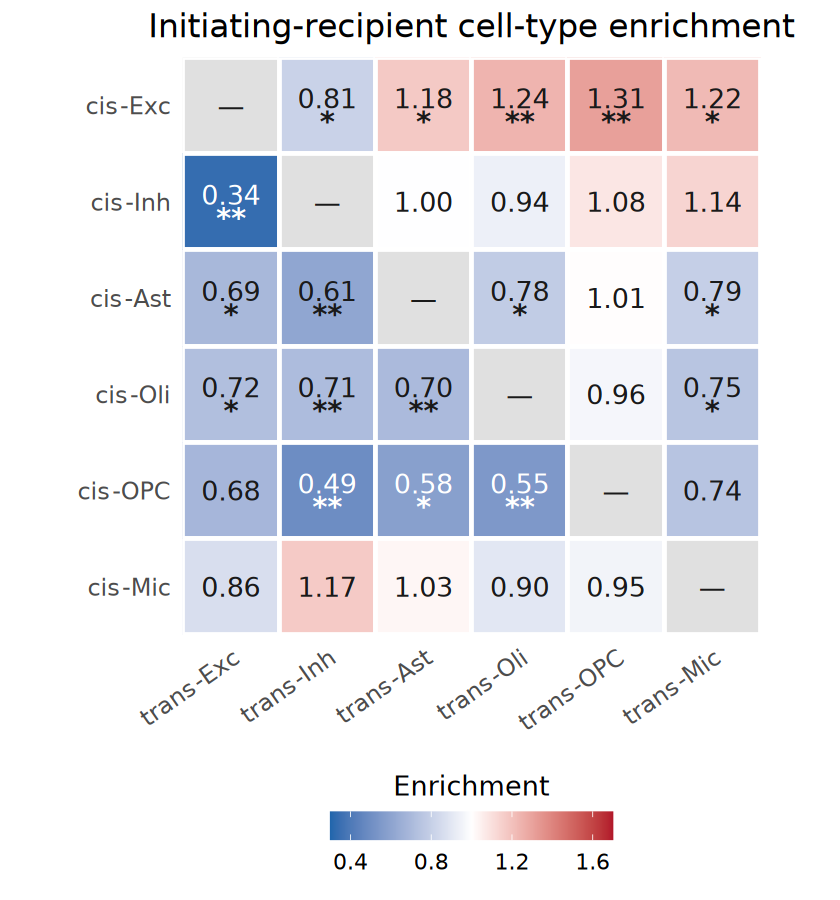

In [2]:
res$cis_cell <- factor(res$cis_cell, levels = rev(levels(res$cis_cell)))
res$tile_label <- ifelse(is.na(res$enrichment), "\u2014", sprintf("%.2f", res$enrichment))
dev_max <- ceiling(max(abs(res$enrichment - 1), na.rm = TRUE) * 10) / 10
res$text_col <- ifelse(!is.na(res$enrichment) & abs(res$enrichment - 1) > 0.6 * dev_max,
                       "white", "grey10")
res$vj <- ifelse(res$sig == "", 0.5, 0.15)
axis_lab <- function(prefix) function(x) parse(text = paste0("italic('", prefix, "')*'-", x, "'"))

p <- ggplot(res, aes(x = trans_cell, y = cis_cell, fill = enrichment)) +
  geom_tile(colour = "white", linewidth = 1) +
  geom_text(aes(label = tile_label, colour = text_col, vjust = vj), size = 5.5) +
  geom_text(aes(label = sig, colour = text_col), size = 6, vjust = 1.25, fontface = "bold") +
  scale_fill_gradient2(low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 1,
                       limits = c(max(0, 1 - dev_max), 1 + dev_max), oob = squish,
                       na.value = "grey88", name = "Enrichment") +
  scale_colour_identity() +
  scale_x_discrete(labels = axis_lab("trans"), expand = c(0, 0)) +
  scale_y_discrete(labels = axis_lab("cis"), expand = c(0, 0)) +
  coord_fixed() +
  labs(title = "Initiating-recipient cell-type enrichment", x = NULL, y = NULL) +
  theme_minimal(base_size = 16) +
  theme(plot.title = element_text(hjust = 0.5),
        axis.text.x = element_text(angle = 35, hjust = 1, vjust = 1, size = 14),
        axis.text.y = element_text(size = 14),
        panel.grid = element_blank(), legend.position = "bottom") +
  guides(fill = guide_colourbar(title.position = "top", title.hjust = 0.5,
                                barwidth = grid::unit(6, "cm")))

options(repr.plot.width = 7, repr.plot.height = 7.5)
p